In [1]:
print("E-commerce Analytics Project")

E-commerce Analytics Project


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data"

customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
orders = pd.read_csv(DATA_DIR / "orders.csv")
order_items = pd.read_csv(DATA_DIR / "order_items.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [4]:
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)

Customers: (10000, 8)
Products: (498, 6)
Orders: (30000, 7)
Order Items: (74485, 8)


In [5]:
print("CUSTOMERS")
display(customers.head())

print("\nPRODUCTS")
display(products.head())

print("\nORDERS")
display(orders.head())

print("\nORDER ITEMS")
display(order_items.head())

CUSTOMERS


,customer_id,customer_name,email,gender,age,city,state,signup_date
0,1,Anvi Konda,liamchaudry@example.net,Other,35,Bengaluru,Karnataka,2025-08-19
1,2,Pahal Balay,chandertejas@example.org,Male,65,Coimbatore,Tamil Nadu,2025-12-05
2,3,Rushil Saini,saumyamall@example.org,Other,45,Bengaluru,Karnataka,2025-03-29
3,4,Pahal Oak,nachiket35@example.org,Male,31,Mumbai,Maharashtra,2025-12-24
4,5,Jagrati Padmanabhan,caleb78@example.org,Other,30,Chennai,Tamil Nadu,2024-01-14



PRODUCTS


,product_id,product_name,category,subcategory,cost_price,selling_price
0,1,Repellendus Tablet,Electronics,Tablet,11031.17,17046.14
1,2,A Smartwatch,Electronics,Smartwatch,3431.48,4558.22
2,3,Odio Headphones,Electronics,Headphones,4782.88,6515.33
3,4,Delectus Headphones,Electronics,Headphones,3986.41,5407.84
4,5,Provident Laptop,Electronics,Laptop,6159.80,8223.39



ORDERS


,order_id,customer_id,order_date,status,payment_method,shipping_days,delivery_date
0,1,1254,2025-10-25 04:59:38.024650,Delivered,Wallet,4,2025-10-29 04:59:38.024650
1,2,8110,2025-02-16 02:51:50.214857,Processing,UPI,8,NaN
2,3,9628,2024-12-08 10:33:28.979945,Delivered,Net Banking,3,2024-12-11 10:33:28.979945
3,4,822,2025-03-13 08:36:06.197005,Shipped,Cash on Delivery,2,NaN
4,5,3082,2024-01-03 23:25:00.398496,Cancelled,Cash on Delivery,7,NaN



ORDER ITEMS


,order_item_id,order_id,product_id,quantity,unit_price,discount_percent,revenue,profit
0,1,1,359,1,10838.69,5,10296.76,948.37
1,2,2,339,2,3330.47,0,6660.94,1004.82
2,3,2,181,1,21143.52,5,20086.34,5137.91
3,4,2,99,1,14664.20,20,11731.36,511.55
4,5,3,199,1,339.35,15,288.45,23.64


In [6]:
print("Customers:")
customers.info()

print("\nProducts:")
products.info()

print("\nOrders:")
orders.info()

print("\nOrder Items:")
order_items.info()

Customers:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customer_id    10000 non-null  int64
 1   customer_name  10000 non-null  str  
 2   email          10000 non-null  str  
 3   gender         10000 non-null  str  
 4   age            10000 non-null  int64
 5   city           10000 non-null  str  
 6   state          10000 non-null  str  
 7   signup_date    10000 non-null  str  
dtypes: int64(2), str(6)
memory usage: 625.1 KB

Products:
<class 'pandas.DataFrame'>
RangeIndex: 498 entries, 0 to 497
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_id     498 non-null    int64  
 1   product_name   498 non-null    str    
 2   category       498 non-null    str    
 3   subcategory    498 non-null    str    
 4   cost_price     498 non-null    float64
 5   selling_

In [7]:
print("Missing values - Customers")
display(customers.isnull().sum())

print("Missing values - Products")
display(products.isnull().sum())

print("Missing values - Orders")
display(orders.isnull().sum())

print("Missing values - Order Items")
display(order_items.isnull().sum())

Missing values - Customers


customer_id      0
customer_name    0
email            0
gender           0
age              0
city             0
state            0
signup_date      0
dtype: int64

Missing values - Products


product_id       0
product_name     0
category         0
subcategory      0
cost_price       0
selling_price    0
dtype: int64

Missing values - Orders


order_id              0
customer_id           0
order_date            0
status                0
payment_method        0
shipping_days         0
delivery_date     14883
dtype: int64

Missing values - Order Items


order_item_id       0
order_id            0
product_id          0
quantity            0
unit_price          0
discount_percent    0
revenue             0
profit              0
dtype: int64

In [8]:
print("Customer duplicates:", customers.duplicated().sum())
print("Product duplicates:", products.duplicated().sum())
print("Order duplicates:", orders.duplicated().sum())
print("Order item duplicates:", order_items.duplicated().sum())

Customer duplicates: 0
Product duplicates: 0
Order duplicates: 0
Order item duplicates: 0


In [9]:
print("Order Status:")
print(orders["status"].value_counts())

print("\nPayment Methods:")
print(orders["payment_method"].value_counts())

print("\nProduct Categories:")
print(products["category"].value_counts())

print("\nCustomer Gender:")
print(customers["gender"].value_counts())

Order Status:
status
Delivered     15117
Returned       3829
Cancelled      3713
Shipped        3688
Processing     3653
Name: count, dtype: int64

Payment Methods:
payment_method
UPI                 5094
Debit Card          5086
Wallet              5006
Net Banking         4957
Credit Card         4953
Cash on Delivery    4904
Name: count, dtype: int64

Product Categories:
category
Electronics       83
Home & Kitchen    83
Fashion           83
Beauty            83
Sports            83
Books             83
Name: count, dtype: int64

Customer Gender:
gender
Male      3340
Other     3339
Female    3321
Name: count, dtype: int64


In [10]:
total_revenue = order_items["revenue"].sum()
total_profit = order_items["profit"].sum()

print(f"Total Revenue : ₹{total_revenue:,.2f}")
print(f"Total Profit  : ₹{total_profit:,.2f}")

print(
    f"Profit Margin : {(total_profit / total_revenue) * 100:.2f}%"
)

Total Revenue : ₹1,417,728,748.30
Total Profit  : ₹243,064,401.11
Profit Margin : 17.14%


In [11]:
customers["signup_date"] = pd.to_datetime(
    customers["signup_date"]
)

orders["order_date"] = pd.to_datetime(
    orders["order_date"]
)

orders["delivery_date"] = pd.to_datetime(
    orders["delivery_date"]
)

print("Date columns converted successfully.")

print("\nCustomers:")
print(customers["signup_date"].dtype)

print("\nOrders:")
print(orders["order_date"].dtype)
print(orders["delivery_date"].dtype)

Date columns converted successfully.

Customers:
datetime64[us]

Orders:
datetime64[us]
datetime64[us]


In [12]:
invalid_customers = ~orders["customer_id"].isin(
    customers["customer_id"]
)

invalid_products = ~order_items["product_id"].isin(
    products["product_id"]
)

invalid_orders = ~order_items["order_id"].isin(
    orders["order_id"]
)

print("Orders with invalid customer IDs:",
      invalid_customers.sum())

print("Order items with invalid product IDs:",
      invalid_products.sum())

print("Order items with invalid order IDs:",
      invalid_orders.sum())

Orders with invalid customer IDs: 0
Order items with invalid product IDs: 0
Order items with invalid order IDs: 0


In [13]:
calculated_revenue = (
    order_items["unit_price"]
    * order_items["quantity"]
    * (1 - order_items["discount_percent"] / 100)
)

calculated_profit = (
    calculated_revenue
    - (
        order_items["quantity"]
        * order_items["product_id"].map(
            products.set_index("product_id")["cost_price"]
        )
    )
)

print(
    "Revenue calculation correct:",
    np.allclose(
        order_items["revenue"],
        calculated_revenue,
        rtol=1e-5
    )
)

print(
    "Profit calculation correct:",
    np.allclose(
        order_items["profit"],
        calculated_profit,
        rtol=1e-5
    )
)

Revenue calculation correct: False
Profit calculation correct: False


In [14]:
price_check = order_items.merge(
    products[["product_id", "selling_price", "cost_price"]],
    on="product_id",
    how="left"
)

price_check["price_difference"] = (
    price_check["unit_price"]
    - price_check["selling_price"]
)

print(
    "Rows with price mismatch:",
    (price_check["price_difference"].abs() > 0.01).sum()
)

print(
    "Total order item rows:",
    len(price_check)
)

display(
    price_check[
        price_check["price_difference"].abs() > 0.01
    ].head(10)
)

Rows with price mismatch: 0
Total order item rows: 74485


,order_item_id,order_id,product_id,quantity,unit_price,discount_percent,revenue,profit,selling_price,cost_price,price_difference


In [15]:
row = order_items.iloc[0]

print("Order item:")
print(row)

product = products[
    products["product_id"] == row["product_id"]
].iloc[0]

print("\nMatching product:")
print(product)

expected_revenue = (
    row["unit_price"]
    * row["quantity"]
    * (1 - row["discount_percent"] / 100)
)

print("\nStored revenue:", row["revenue"])
print("Expected revenue:", expected_revenue)

Order item:
order_item_id           1.00
order_id                1.00
product_id            359.00
quantity                1.00
unit_price          10838.69
discount_percent        5.00
revenue             10296.76
profit                948.37
Name: 0, dtype: float64

Matching product:
product_id                       359
product_name     Nobis Running Shoes
category                      Sports
subcategory            Running Shoes
cost_price                   9348.39
selling_price               10838.69
Name: 358, dtype: object

Stored revenue: 10296.76
Expected revenue: 10296.7555


In [16]:
product_costs = order_items["product_id"].map(
    products.set_index("product_id")["cost_price"]
)

calculated_revenue = (
    order_items["unit_price"]
    * order_items["quantity"]
    * (1 - order_items["discount_percent"] / 100)
)

calculated_profit = (
    calculated_revenue
    - (order_items["quantity"] * product_costs)
)

# Compare after rounding to 2 decimal places
revenue_check = np.allclose(
    order_items["revenue"],
    calculated_revenue.round(2)
)

profit_check = np.allclose(
    order_items["profit"],
    calculated_profit.round(2)
)

print("Revenue calculation correct:", revenue_check)
print("Profit calculation correct:", profit_check)

Revenue calculation correct: False
Profit calculation correct: False


In [17]:
product_costs = order_items["product_id"].map(
    products.set_index("product_id")["cost_price"]
)

# Recalculate using the same business formula
calculated_revenue = (
    order_items["unit_price"]
    * order_items["quantity"]
    * (1 - order_items["discount_percent"] / 100)
)

calculated_profit = (
    calculated_revenue
    - (order_items["quantity"] * product_costs)
)

# Difference after rounding to currency precision
revenue_difference = (
    order_items["revenue"]
    - calculated_revenue.round(2)
)

profit_difference = (
    order_items["profit"]
    - calculated_profit.round(2)
)

print("Maximum revenue difference:",
      revenue_difference.abs().max())

print("Maximum profit difference:",
      profit_difference.abs().max())

print("\nRevenue mismatches:",
      (revenue_difference.abs() > 0.01).sum())

print("Profit mismatches:",
      (profit_difference.abs() > 0.01).sum())

Maximum revenue difference: 0.010000000002037268
Maximum profit difference: 0.010000000000218279

Revenue mismatches: 175
Profit mismatches: 188


In [18]:
revenue_valid = (
    revenue_difference.abs() <= 0.02
).all()

profit_valid = (
    profit_difference.abs() <= 0.02
).all()

print("Revenue calculation valid:", revenue_valid)
print("Profit calculation valid:", profit_valid)

Revenue calculation valid: True
Profit calculation valid: True


In [19]:
print("Age below 18:",
      (customers["age"] < 18).sum())

print("Age above 100:",
      (customers["age"] > 100).sum())

print("Invalid quantity:",
      (order_items["quantity"] <= 0).sum())

print("Negative revenue:",
      (order_items["revenue"] < 0).sum())

print("Invalid selling price:",
      (products["selling_price"] <= 0).sum())

print("Invalid cost price:",
      (products["cost_price"] <= 0).sum())

print("Invalid discount:",
      ((order_items["discount_percent"] < 0) |
       (order_items["discount_percent"] > 100)).sum())

Age below 18: 0
Age above 100: 0
Invalid quantity: 0
Negative revenue: 0
Invalid selling price: 0
Invalid cost price: 0
Invalid discount: 0


In [20]:
total_revenue = order_items["revenue"].sum()
total_profit = order_items["profit"].sum()

total_orders = orders["order_id"].nunique()
total_customers = customers["customer_id"].nunique()

total_products = products["product_id"].nunique()

average_order_value = total_revenue / total_orders

profit_margin = (
    total_profit / total_revenue
) * 100

print("E-COMMERCE BUSINESS KPIs")
print("=" * 40)

print(f"Total Revenue       : ₹{total_revenue:,.2f}")
print(f"Total Profit        : ₹{total_profit:,.2f}")
print(f"Total Orders        : {total_orders:,}")
print(f"Total Customers     : {total_customers:,}")
print(f"Total Products      : {total_products:,}")
print(f"Average Order Value : ₹{average_order_value:,.2f}")
print(f"Profit Margin       : {profit_margin:.2f}%")

E-COMMERCE BUSINESS KPIs
Total Revenue       : ₹1,417,728,748.30
Total Profit        : ₹243,064,401.11
Total Orders        : 30,000
Total Customers     : 10,000
Total Products      : 498
Average Order Value : ₹47,257.62
Profit Margin       : 17.14%


In [21]:
status_summary = (
    orders["status"]
    .value_counts()
    .reset_index()
)

status_summary.columns = [
    "status",
    "order_count"
]

status_summary["percentage"] = (
    status_summary["order_count"]
    / total_orders
    * 100
)

status_summary

,status,order_count,percentage
0,Delivered,15117,50.390000
1,Returned,3829,12.763333
2,Cancelled,3713,12.376667
3,Shipped,3688,12.293333
4,Processing,3653,12.176667


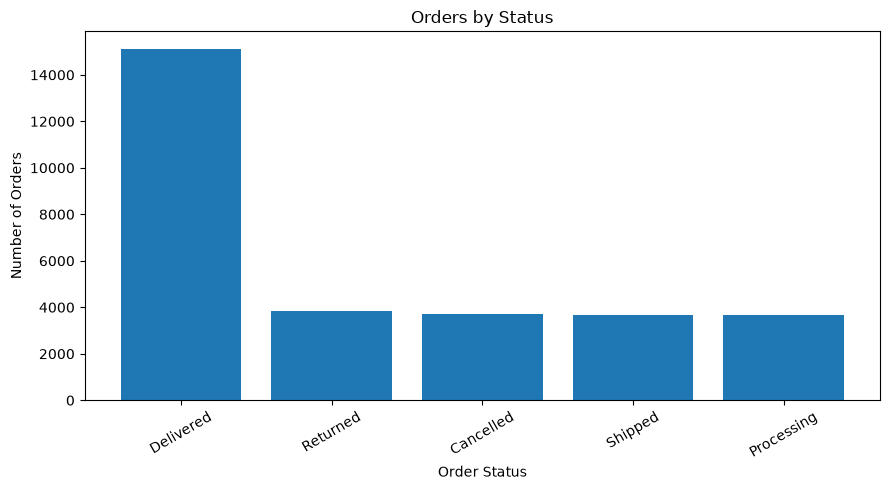

In [22]:
plt.figure(figsize=(9, 5))

plt.bar(
    status_summary["status"],
    status_summary["order_count"]
)

plt.title("Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [23]:
cancelled_orders = (
    orders["status"] == "Cancelled"
).sum()

returned_orders = (
    orders["status"] == "Returned"
).sum()

cancellation_rate = (
    cancelled_orders / total_orders
) * 100

return_rate = (
    returned_orders / total_orders
) * 100

print(f"Cancellation Rate : {cancellation_rate:.2f}%")
print(f"Return Rate       : {return_rate:.2f}%")

Cancellation Rate : 12.38%
Return Rate       : 12.76%


In [24]:
orders["year_month"] = (
    orders["order_date"]
    .dt.to_period("M")
)

In [25]:
order_sales = orders.merge(
    order_items,
    on="order_id",
    how="inner"
)

In [26]:
monthly_revenue = (
    order_sales
    .groupby("year_month")["revenue"]
    .sum()
    .reset_index()
)

monthly_revenue["year_month"] = (
    monthly_revenue["year_month"]
    .astype(str)
)

monthly_revenue.head()

,year_month,revenue
0,2024-01,59797765.54
1,2024-02,53884335.25
2,2024-03,61528554.57
3,2024-04,60481619.97
4,2024-05,63440885.95


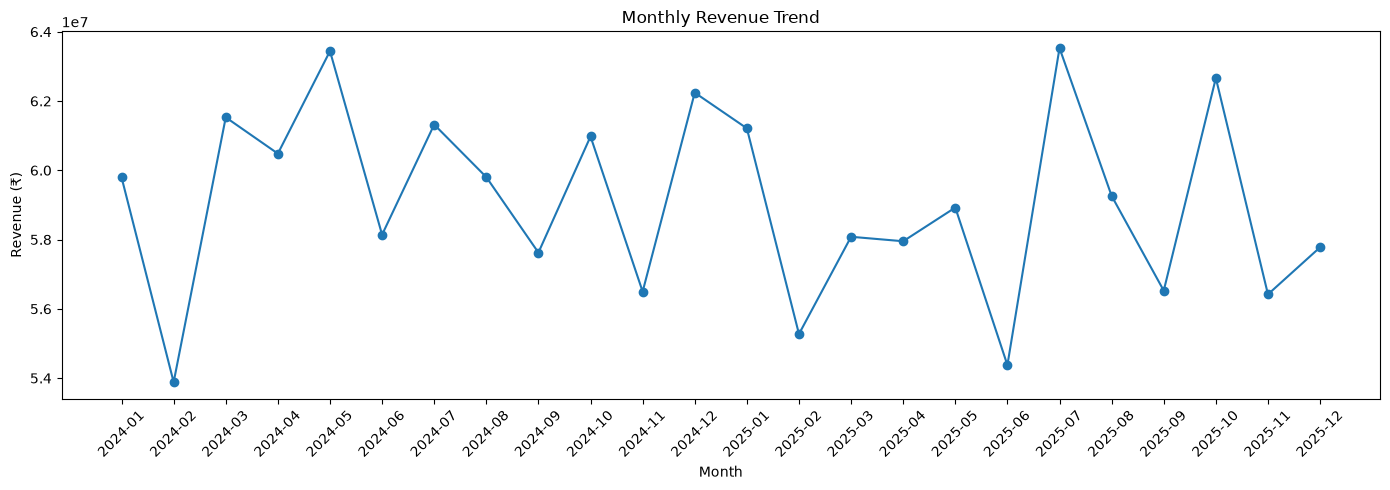

In [27]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_revenue["year_month"],
    monthly_revenue["revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [28]:
product_sales = order_items.merge(
    products,
    on="product_id",
    how="left"
)

In [29]:
top_products = (
    product_sales
    .groupby(
        ["product_id", "product_name"]
    )
    .agg(
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        quantity_sold=("quantity", "sum")
    )
    .sort_values(
        "revenue",
        ascending=False
    )
    .head(10)
    .reset_index()
)

top_products

,product_id,product_name,revenue,profit,quantity_sold
0,118,Iusto Mixer,6525012.18,1805901.68,325
1,73,Atque Headphones,6363670.22,1654054.22,320
2,421,Sequi Non-Fiction,6278792.84,1529278.07,327
3,179,Occaecati Shoes,6201026.33,1668708.57,304
4,430,Saepe Technical,6063387.58,1617953.51,319
5,101,Minima Furniture,5941189.05,1512921.05,325
6,294,Quibusdam Haircare,5891800.15,1484864.83,333
7,90,Veritatis Storage,5856188.72,1702504.88,302
8,68,Hic Laptop,5782131.39,1101903.75,319
9,333,Eaque Fitness Equipment,5724438.24,1250764.67,325


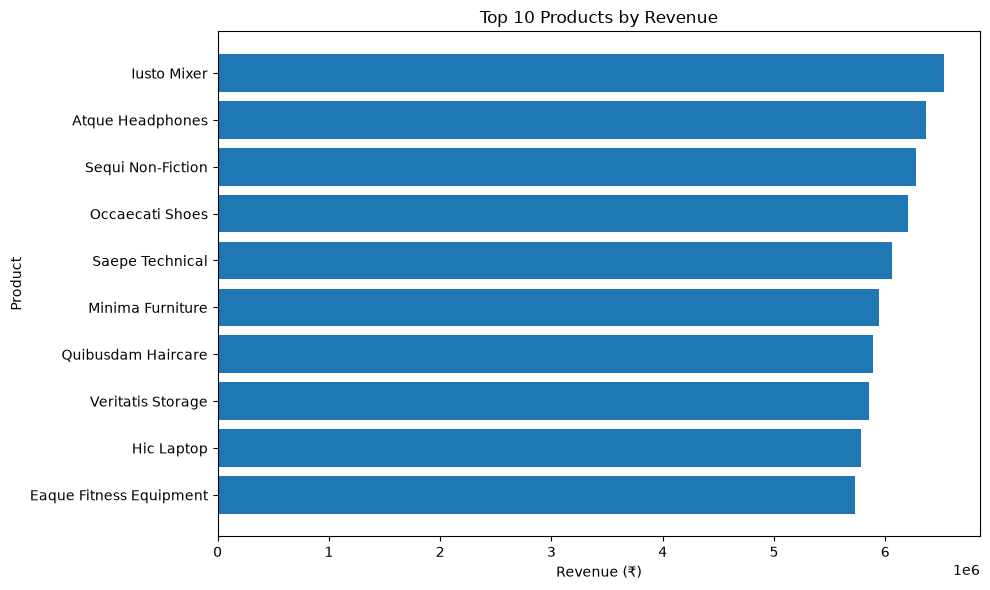

In [30]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_products["product_name"],
    top_products["revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [31]:
unique_buyers = orders["customer_id"].nunique()

purchase_rate = (
    unique_buyers / total_customers
) * 100

print(f"Customers who placed orders : {unique_buyers:,}")
print(f"Customer purchase rate      : {purchase_rate:.2f}%")

Customers who placed orders : 9,534
Customer purchase rate      : 95.34%


In [32]:
customer_orders = (
    orders
    .groupby("customer_id")["order_id"]
    .nunique()
    .reset_index(name="order_count")
)

customer_orders["customer_type"] = np.where(
    customer_orders["order_count"] == 1,
    "One-time",
    "Repeat"
)

customer_segments = (
    customer_orders["customer_type"]
    .value_counts()
    .reset_index()
)

customer_segments.columns = [
    "customer_type",
    "customer_count"
]

customer_segments["percentage"] = (
    customer_segments["customer_count"]
    / customer_segments["customer_count"].sum()
    * 100
)

customer_segments

,customer_type,customer_count,percentage
0,Repeat,8042,84.350745
1,One-time,1492,15.649255


In [33]:
customer_revenue = (
    order_sales
    .groupby("customer_id")
    .agg(
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique")
    )
    .sort_values(
        "total_revenue",
        ascending=False
    )
    .head(10)
    .reset_index()
)

customer_revenue

,customer_id,total_revenue,total_profit,total_orders
0,9592,696315.29,92166.47,8
1,1627,687506.44,116961.82,13
2,7087,667614.73,102094.44,11
3,591,611091.26,115419.29,8
4,8295,587954.93,105621.13,8
5,3333,584181.13,90712.93,9
6,163,579444.06,114412.97,8
7,808,578657.27,96631.75,11
8,8532,560347.95,131216.79,10
9,2994,554302.49,75304.63,9


In [34]:
top_customers = customer_revenue.merge(
    customers[
        ["customer_id", "customer_name", "city", "state"]
    ],
    on="customer_id",
    how="left"
)

top_customers

,customer_id,total_revenue,total_profit,total_orders,customer_name,city,state
0,9592,696315.29,92166.47,8,Riya Pai,Rajkot,Gujarat
1,1627,687506.44,116961.82,13,Nikita Raj,Kozhikode,Kerala
2,7087,667614.73,102094.44,11,Arin Ranganathan,Kozhikode,Kerala
3,591,611091.26,115419.29,8,Darpan Parekh,Kochi,Kerala
4,8295,587954.93,105621.13,8,Lohit Handa,Durgapur,West Bengal
5,3333,584181.13,90712.93,9,Yatan Morar,Madurai,Tamil Nadu
6,163,579444.06,114412.97,8,Oscar Dua,Hyderabad,Telangana
7,808,578657.27,96631.75,11,Jatin Jha,Hyderabad,Telangana
8,8532,560347.95,131216.79,10,Qasim Bhandari,Pune,Maharashtra
9,2994,554302.49,75304.63,9,Upma Khalsa,Thiruvananthapuram,Kerala


In [35]:
state_sales = (
    order_sales
    .merge(
        customers[
            ["customer_id", "state"]
        ],
        on="customer_id",
        how="left"
    )
    .groupby("state")
    .agg(
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        orders=("order_id", "nunique")
    )
    .sort_values(
        "revenue",
        ascending=False
    )
    .reset_index()
)

state_sales

,state,revenue,profit,orders
0,West Bengal,1.500149e+08,25447822.73,3215
1,Karnataka,1.490816e+08,25420607.78,3123
2,Kerala,1.466529e+08,25411391.64,3114
3,Delhi,1.461132e+08,25365943.74,3070
4,Uttar Pradesh,1.418986e+08,24373840.27,3015
5,Gujarat,1.406378e+08,24083732.48,2961
6,Maharashtra,1.389284e+08,23621293.19,2957
7,Rajasthan,1.384264e+08,23348999.57,2914
8,Telangana,1.340566e+08,23225220.70,2850
9,Tamil Nadu,1.319184e+08,22765549.01,2781


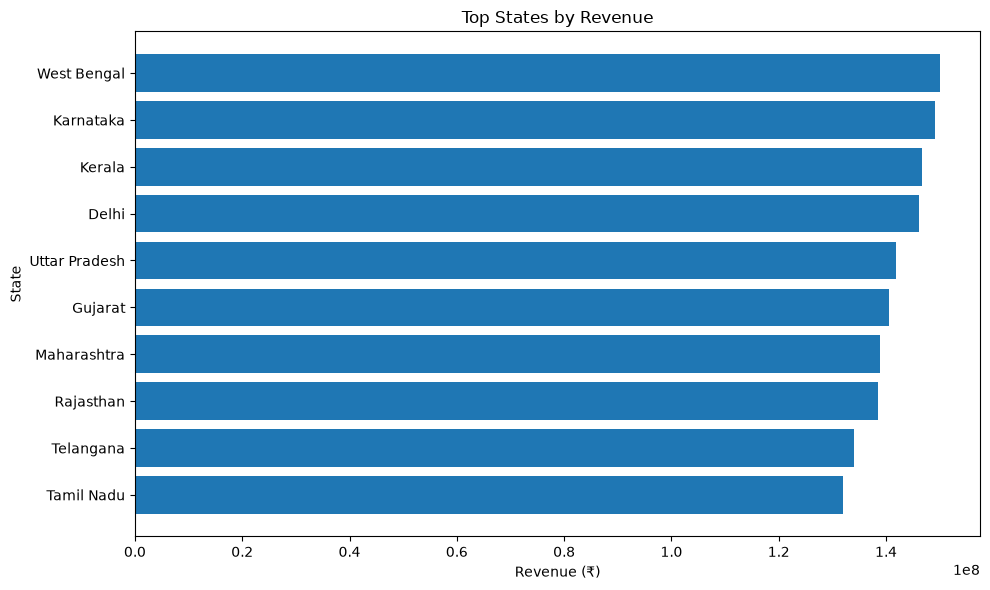

In [36]:
top_states = state_sales.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_states["state"],
    top_states["revenue"]
)

plt.title("Top States by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("State")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [37]:
category_sales = (
    product_sales
    .groupby("category")
    .agg(
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        quantity_sold=("quantity", "sum")
    )
    .sort_values(
        "revenue",
        ascending=False
    )
    .reset_index()
)

category_sales

,category,revenue,profit,quantity_sold
0,Fashion,2.489157e+08,48805020.36,24743
1,Beauty,2.457020e+08,43668079.78,24954
2,Home & Kitchen,2.352953e+08,41366950.29,25067
3,Books,2.348161e+08,38732803.97,25019
4,Electronics,2.339353e+08,38206539.99,24786
5,Sports,2.190644e+08,32285006.72,24811


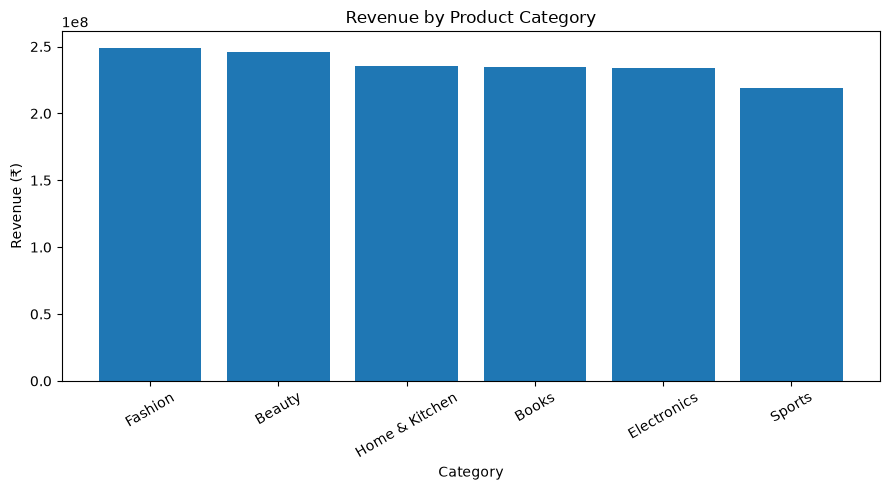

In [38]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_sales["category"],
    category_sales["revenue"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue (₹)")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [39]:
discount_analysis = (
    order_items
    .groupby("discount_percent")
    .agg(
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        quantity_sold=("quantity", "sum")
    )
    .reset_index()
)

discount_analysis["profit_margin"] = (
    discount_analysis["profit"]
    / discount_analysis["revenue"]
    * 100
)

discount_analysis

,discount_percent,revenue,profit,quantity_sold,profit_margin
0,0,2.711157e+08,74683789.30,24736,27.546834
1,5,2.556750e+08,60719354.48,24816,23.748652
2,10,2.436077e+08,47477131.91,24951,19.489174
3,15,2.277328e+08,33345059.27,24742,14.642186
4,20,2.184524e+08,20666292.03,25304,9.460320
5,25,2.011452e+08,6172774.12,24831,3.068815


In [45]:
reference_date = orders["order_date"].max() + pd.Timedelta(days=1)

rfm = (
    order_sales
    .groupby("customer_id")
    .agg(
        last_purchase=("order_date", "max"),
        frequency=("order_id", "nunique"),
        monetary=("revenue", "sum")
    )
    .reset_index()
)


rfm["recency"] = (
    reference_date - rfm["last_purchase"]
).dt.days


rfm = rfm[
    ["customer_id", "recency", "frequency", "monetary"]
]

rfm.head(10)

,customer_id,recency,frequency,monetary
0,1,574,2,147446.08
1,2,200,2,117348.02
2,3,311,2,44822.04
3,4,537,1,42948.72
4,5,197,4,164301.83
5,6,25,2,45718.16
6,7,649,3,114678.62
7,8,112,6,278190.66
8,9,671,2,62177.50
9,10,6,3,122510.31


In [46]:
rfm["R_score"] = pd.qcut(
    rfm["recency"],
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

rfm.head(10)

,customer_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
0,1,574,2,147446.08,1,1,3,113
1,2,200,2,117348.02,3,1,3,313
2,3,311,2,44822.04,2,1,1,211
3,4,537,1,42948.72,1,1,1,111
4,5,197,4,164301.83,3,4,4,344
5,6,25,2,45718.16,5,1,1,511
6,7,649,3,114678.62,1,3,3,133
7,8,112,6,278190.66,4,5,5,455
8,9,671,2,62177.50,1,1,1,111
9,10,6,3,122510.31,5,3,3,533


In [47]:
def segment_customer(row):
    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif r >= 4 and f >= 2:
        return "Potential Loyalists"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2:
        return "Lost Customers"

    elif m >= 4:
        return "High Value"

    else:
        return "Regular Customers"


rfm["segment"] = rfm.apply(segment_customer, axis=1)


rfm.head(10)

,customer_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,segment
0,1,574,2,147446.08,1,1,3,113,Lost Customers
1,2,200,2,117348.02,3,1,3,313,Regular Customers
2,3,311,2,44822.04,2,1,1,211,Lost Customers
3,4,537,1,42948.72,1,1,1,111,Lost Customers
4,5,197,4,164301.83,3,4,4,344,Loyal Customers
5,6,25,2,45718.16,5,1,1,511,Regular Customers
6,7,649,3,114678.62,1,3,3,133,At Risk
7,8,112,6,278190.66,4,5,5,455,Champions
8,9,671,2,62177.50,1,1,1,111,Lost Customers
9,10,6,3,122510.31,5,3,3,533,Potential Loyalists


In [48]:
segment_summary = (
    rfm["segment"]
    .value_counts()
    .reset_index()
)

segment_summary.columns = ["segment", "customer_count"]

segment_summary["percentage"] = (
    segment_summary["customer_count"] /
    segment_summary["customer_count"].sum() * 100
).round(2)

segment_summary

,segment,customer_count,percentage
0,Lost Customers,2295,24.07
1,Champions,1704,17.87
2,At Risk,1515,15.89
3,Potential Loyalists,1325,13.90
4,Loyal Customers,1299,13.62
5,Regular Customers,1222,12.82
6,High Value,174,1.83


In [49]:
segment_value = (
    rfm
    .groupby("segment")
    .agg(
        customer_count=("customer_id", "nunique"),
        total_revenue=("monetary", "sum")
    )
    .reset_index()
)


segment_value["revenue_percentage"] = (
    segment_value["total_revenue"] /
    segment_value["total_revenue"].sum() * 100
).round(2)


segment_value["avg_customer_revenue"] = (
    segment_value["total_revenue"] /
    segment_value["customer_count"]
).round(2)

segment_value = segment_value.sort_values(
    "total_revenue",
    ascending=False
)

segment_value

,segment,customer_count,total_revenue,revenue_percentage,avg_customer_revenue
1,Champions,1704,4.505887e+08,31.78,264429.99
0,At Risk,1515,2.688876e+08,18.97,177483.59
4,Loyal Customers,1299,2.444738e+08,17.24,188201.56
3,Lost Customers,2295,1.636288e+08,11.54,71297.97
5,Potential Loyalists,1325,1.612706e+08,11.38,121713.69
6,Regular Customers,1222,9.503809e+07,6.70,77772.58
2,High Value,174,3.384100e+07,2.39,194488.52


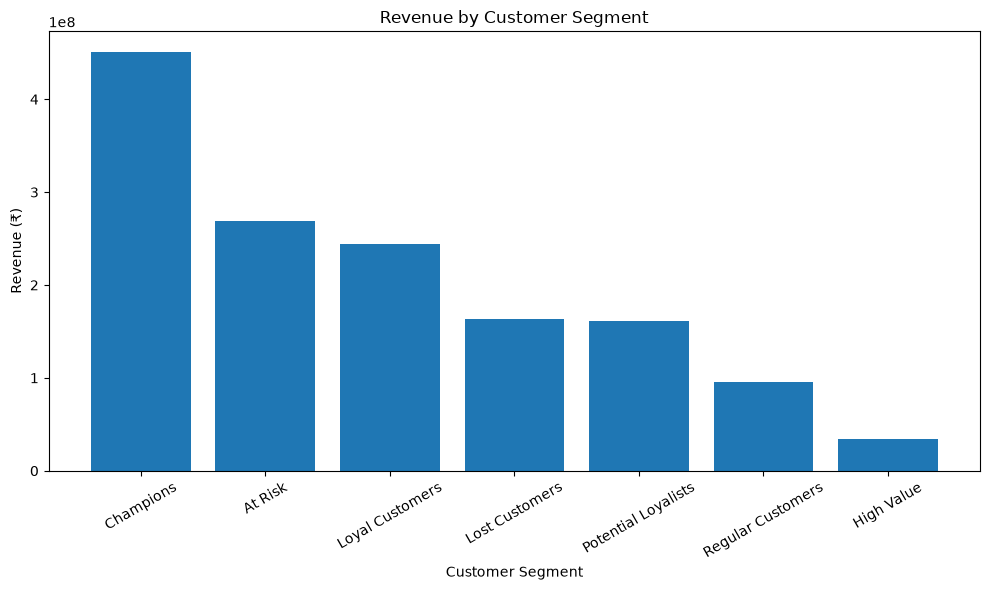

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    segment_value["segment"],
    segment_value["total_revenue"]
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [51]:
delivered_orders = orders[
    orders["status"] == "Delivered"
].copy()

delivery_summary = pd.DataFrame({
    "Metric": [
        "Delivered Orders",
        "Average Shipping Days",
        "Minimum Shipping Days",
        "Maximum Shipping Days",
        "On-Time Delivery (<= 5 days)"
    ],
    "Value": [
        len(delivered_orders),
        delivered_orders["shipping_days"].mean(),
        delivered_orders["shipping_days"].min(),
        delivered_orders["shipping_days"].max(),
        (
            delivered_orders["shipping_days"].le(5).mean() * 100
        )
    ]
})

delivery_summary

,Metric,Value
0,Delivered Orders,15117.000000
1,Average Shipping Days,4.974135
2,Minimum Shipping Days,2.000000
3,Maximum Shipping Days,8.000000
4,On-Time Delivery (<= 5 days),57.729708


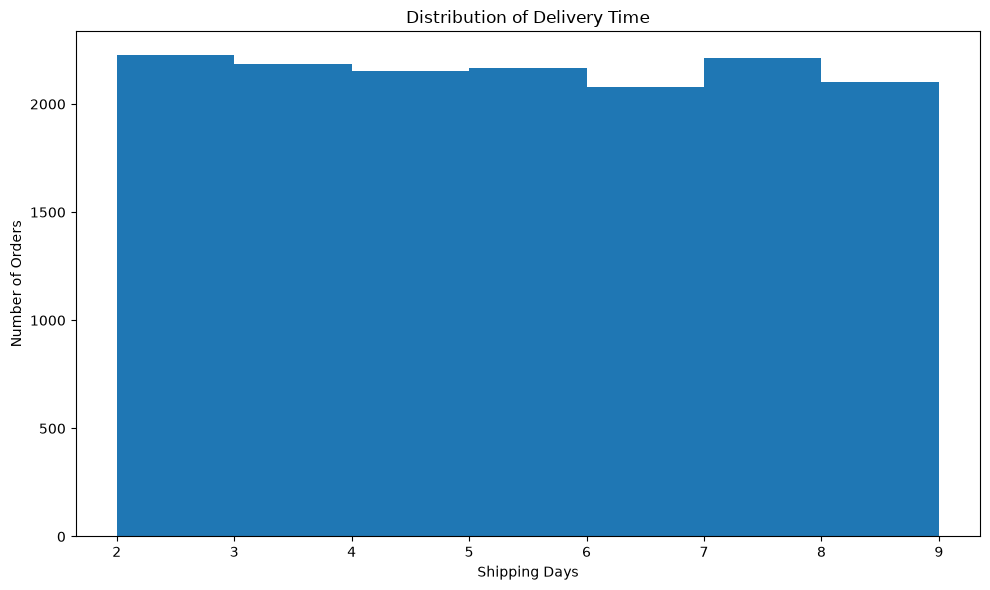

In [52]:
plt.figure(figsize=(10, 6))

plt.hist(
    delivered_orders["shipping_days"],
    bins=range(
        int(delivered_orders["shipping_days"].min()),
        int(delivered_orders["shipping_days"].max()) + 2
    )
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Shipping Days")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [53]:
total_orders = orders["order_id"].nunique()

cancelled_orders = orders[
    orders["status"] == "Cancelled"
]["order_id"].nunique()

returned_orders = orders[
    orders["status"] == "Returned"
]["order_id"].nunique()

cancellation_rate = cancelled_orders / total_orders * 100
return_rate = returned_orders / total_orders * 100

print(f"Total Orders       : {total_orders:,}")
print(f"Cancelled Orders   : {cancelled_orders:,}")
print(f"Returned Orders    : {returned_orders:,}")
print(f"Cancellation Rate  : {cancellation_rate:.2f}%")
print(f"Return Rate        : {return_rate:.2f}%")

Total Orders       : 30,000
Cancelled Orders   : 3,713
Returned Orders    : 3,829
Cancellation Rate  : 12.38%
Return Rate        : 12.76%


In [54]:
status_revenue = (
    order_sales
    .groupby("status")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("revenue", ascending=False)
)

status_revenue

,status,orders,revenue,profit
1,Delivered,15117,7.141648e+08,1.221391e+08
3,Returned,3829,1.819530e+08,3.148783e+07
4,Shipped,3688,1.756573e+08,2.990568e+07
2,Processing,3653,1.732143e+08,3.012399e+07
0,Cancelled,3713,1.727394e+08,2.940780e+07


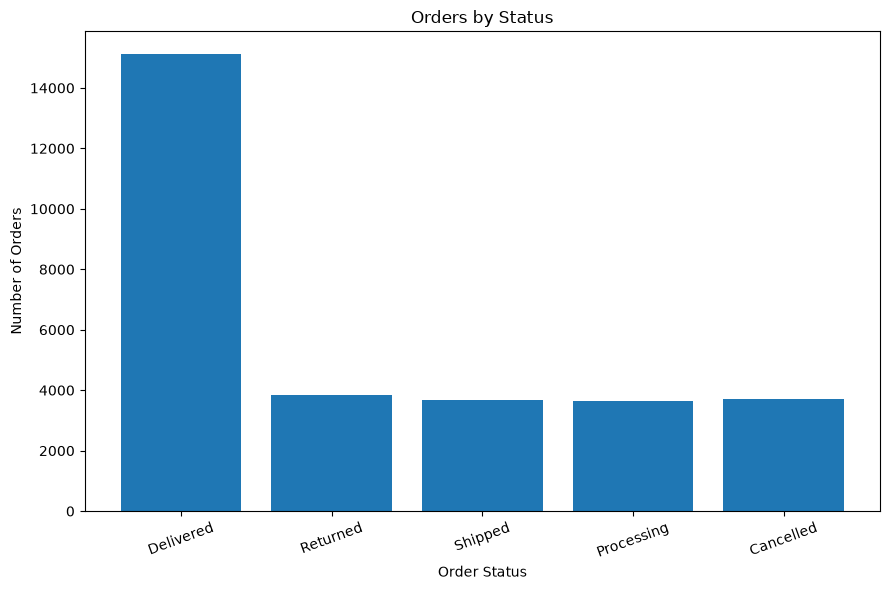

In [55]:
plt.figure(figsize=(9, 6))

plt.bar(
    status_revenue["status"],
    status_revenue["orders"]
)

plt.title("Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [56]:
payment_analysis = (
    order_sales
    .groupby("payment_method")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum")
    )
    .reset_index()
)

payment_analysis["revenue_percentage"] = (
    payment_analysis["revenue"] /
    payment_analysis["revenue"].sum() * 100
).round(2)

payment_analysis["profit_margin"] = (
    payment_analysis["profit"] /
    payment_analysis["revenue"] * 100
).round(2)

payment_analysis = payment_analysis.sort_values(
    "revenue",
    ascending=False
)

payment_analysis

,payment_method,orders,revenue,profit,revenue_percentage,profit_margin
4,UPI,5094,2.422964e+08,41443822.65,17.09,17.10
2,Debit Card,5086,2.402163e+08,41539699.33,16.94,17.29
5,Wallet,5006,2.388404e+08,41332093.44,16.85,17.31
1,Credit Card,4953,2.343558e+08,40100692.47,16.53,17.11
0,Cash on Delivery,4904,2.324875e+08,39583537.92,16.40,17.03
3,Net Banking,4957,2.295323e+08,39064555.30,16.19,17.02


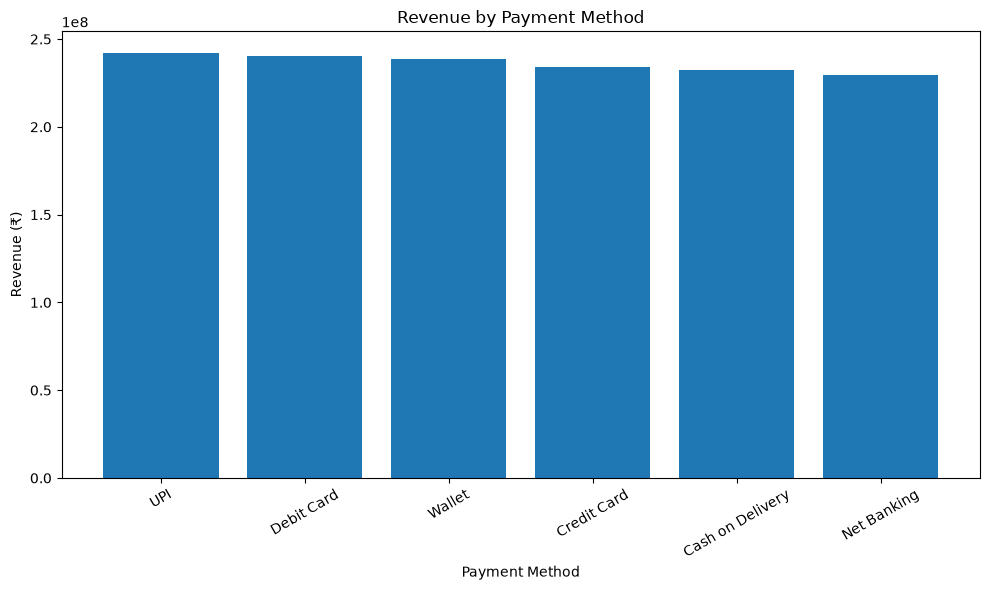

In [57]:
plt.figure(figsize=(10, 6))

plt.bar(
    payment_analysis["payment_method"],
    payment_analysis["revenue"]
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [58]:
product_profitability = (
    product_sales
    .groupby(["product_id", "product_name", "category"])
    .agg(
        quantity_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum")
    )
    .reset_index()
)

product_profitability["profit_margin"] = (
    product_profitability["profit"] /
    product_profitability["revenue"] * 100
).round(2)

product_profitability = product_profitability.sort_values(
    "profit",
    ascending=False
)

product_profitability.head(10)

,product_id,product_name,category,quantity_sold,revenue,profit,profit_margin
117,118,Iusto Mixer,Home & Kitchen,325,6525012.18,1805901.68,27.68
89,90,Veritatis Storage,Home & Kitchen,302,5856188.72,1702504.88,29.07
178,179,Occaecati Shoes,Fashion,304,6201026.33,1668708.57,26.91
72,73,Atque Headphones,Electronics,320,6363670.22,1654054.22,25.99
429,430,Saepe Technical,Books,319,6063387.58,1617953.51,26.68
312,313,Nemo Skincare,Beauty,321,5683627.90,1596020.32,28.08
420,421,Sequi Non-Fiction,Books,327,6278792.84,1529278.07,24.36
100,101,Minima Furniture,Home & Kitchen,325,5941189.05,1512921.05,25.46
293,294,Quibusdam Haircare,Beauty,333,5891800.15,1484864.83,25.20
248,249,Consequuntur Dress,Fashion,300,5524533.41,1484568.41,26.87


In [59]:
high_margin_products = (
    product_profitability[
        product_profitability["quantity_sold"] >= 20
    ]
    .sort_values("profit_margin", ascending=False)
    .head(10)
)

high_margin_products

,product_id,product_name,category,quantity_sold,revenue,profit,profit_margin
221,222,Nemo T-Shirt,Fashion,320,1724952.82,506891.97,29.39
411,412,Exercitationem Sportswear,Sports,290,146861.61,42832.76,29.17
89,90,Veritatis Storage,Home & Kitchen,302,5856188.72,1702504.88,29.07
191,192,Unde Dress,Fashion,297,2267276.55,657881.07,29.02
126,127,Ullam Bedsheet,Home & Kitchen,347,5096551.84,1475079.40,28.94
155,156,Cumque Storage,Home & Kitchen,246,3064922.13,874021.49,28.52
323,324,Laudantium Haircare,Beauty,309,4603797.87,1309459.14,28.44
487,488,Similique Academic,Books,327,1649484.01,467307.07,28.33
11,12,Illum Smartwatch,Electronics,290,2563785.72,723155.72,28.21
16,17,A Tablet,Electronics,323,4372817.50,1230369.77,28.14


In [60]:
product_performance = (
    product_sales
    .groupby(["product_id", "product_name", "category"])
    .agg(
        quantity_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum")
    )
    .reset_index()
)

product_performance["profit_margin"] = (
    product_performance["profit"] /
    product_performance["revenue"] * 100
).round(2)


top_volume_products = (
    product_performance
    .sort_values("quantity_sold", ascending=False)
    .head(10)
)

top_volume_products

,product_id,product_name,category,quantity_sold,revenue,profit,profit_margin
92,93,Doloremque Furniture,Home & Kitchen,380,2792095.58,491165.38,17.59
471,472,Ad Academic,Books,373,4519866.38,295439.96,6.54
418,419,Sit Academic,Books,367,3838413.62,478187.31,12.46
330,331,Praesentium Perfume,Beauty,366,3130621.68,15226.02,0.49
90,91,Impedit Furniture,Home & Kitchen,364,2091179.72,543327.96,25.98
445,446,Laborum Academic,Books,363,449479.57,113853.40,25.33
413,414,Id Fitness Equipment,Sports,363,2429066.70,524431.11,21.59
321,322,Officia Haircare,Beauty,362,411951.22,54345.98,13.19
326,327,Odit Perfume,Beauty,362,5181537.66,1431221.28,27.62
394,395,Possimus Running Shoes,Sports,360,1451302.54,375798.94,25.89


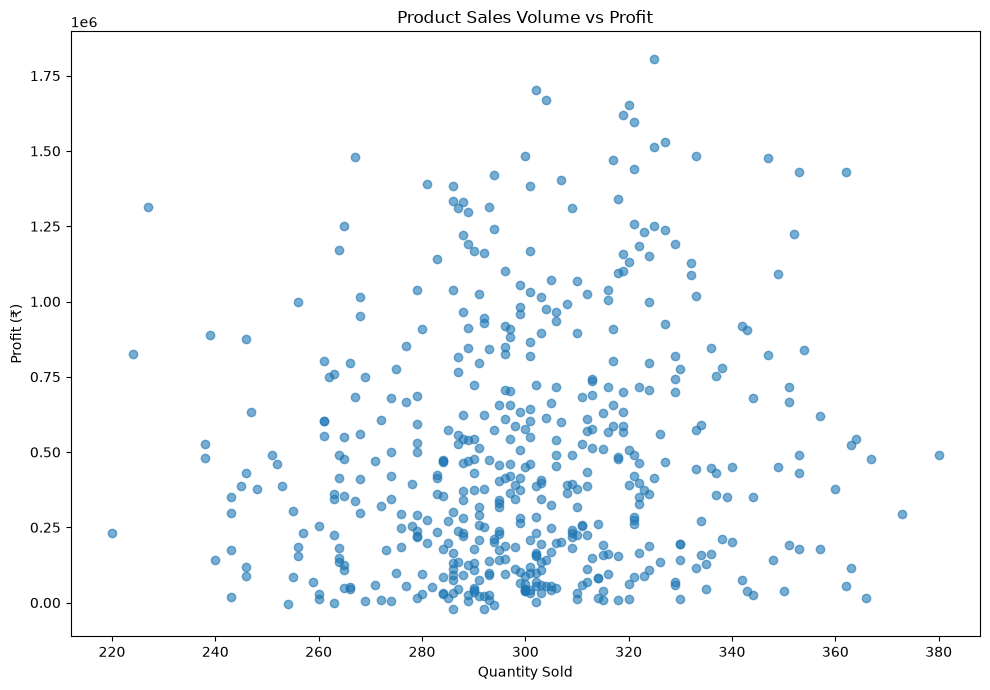

In [61]:
plt.figure(figsize=(10, 7))

plt.scatter(
    product_performance["quantity_sold"],
    product_performance["profit"],
    alpha=0.6
)

plt.title("Product Sales Volume vs Profit")
plt.xlabel("Quantity Sold")
plt.ylabel("Profit (₹)")
plt.tight_layout()
plt.show()

In [62]:
category_performance = (
    product_sales
    .groupby("category")
    .agg(
        quantity_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        profit=("profit", "sum")
    )
    .reset_index()
)

category_performance["profit_margin"] = (
    category_performance["profit"] /
    category_performance["revenue"] * 100
).round(2)

category_performance = category_performance.sort_values(
    "revenue",
    ascending=False
)

category_performance

,category,quantity_sold,revenue,profit,profit_margin
3,Fashion,24743,2.489157e+08,48805020.36,19.61
0,Beauty,24954,2.457020e+08,43668079.78,17.77
4,Home & Kitchen,25067,2.352953e+08,41366950.29,17.58
1,Books,25019,2.348161e+08,38732803.97,16.49
2,Electronics,24786,2.339353e+08,38206539.99,16.33
5,Sports,24811,2.190644e+08,32285006.72,14.74


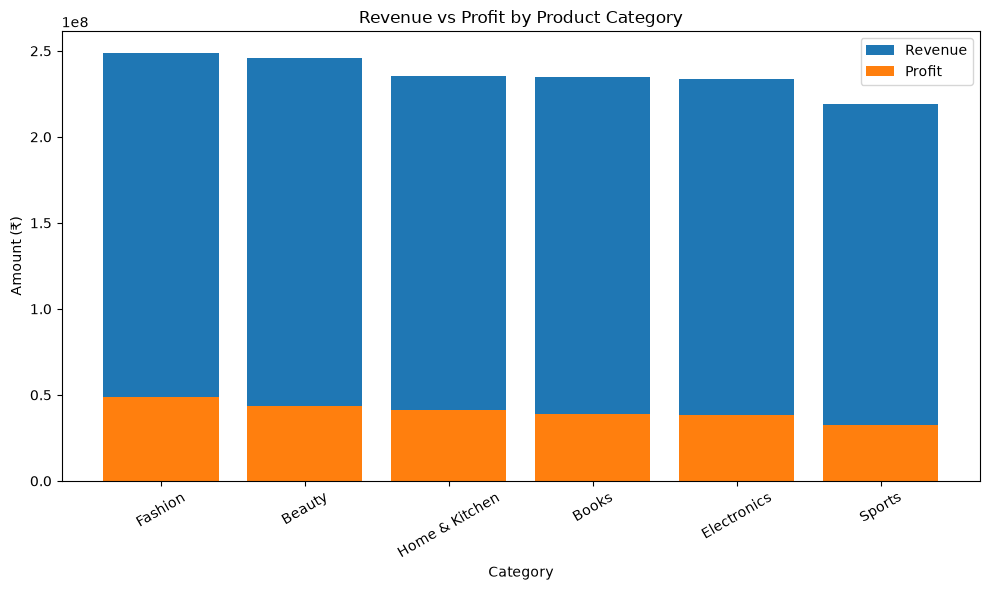

In [63]:
plt.figure(figsize=(10, 6))

x = range(len(category_performance))

plt.bar(
    x,
    category_performance["revenue"],
    label="Revenue"
)

plt.bar(
    x,
    category_performance["profit"],
    label="Profit"
)

plt.xticks(
    x,
    category_performance["category"],
    rotation=30
)

plt.title("Revenue vs Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Amount (₹)")
plt.legend()
plt.tight_layout()
plt.show()

In [64]:
category_performance.sort_values(
    "profit_margin",
    ascending=False
)

,category,quantity_sold,revenue,profit,profit_margin
3,Fashion,24743,2.489157e+08,48805020.36,19.61
0,Beauty,24954,2.457020e+08,43668079.78,17.77
4,Home & Kitchen,25067,2.352953e+08,41366950.29,17.58
1,Books,25019,2.348161e+08,38732803.97,16.49
2,Electronics,24786,2.339353e+08,38206539.99,16.33
5,Sports,24811,2.190644e+08,32285006.72,14.74
